<a href="https://colab.research.google.com/github/Ximearex/AI/blob/main/P6_Operaciones_PDI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Práctica 6. Operaciones aritméticas y lógicas**
**Procesamiento Digital de Imágenes y Laboratorio – FIME UANL**

**Objetivo:** realizar modificaciones a imágenes médicas en el dominio del espacio mediante operaciones aritméticas (suma, resta y multiplicación) y lógicas, incluyendo la ecualización del histograma.

## Imágenes médicas utilizadas

Las imágenes provienen del repositorio público *COVID-19 Image Data Collection* (Cohen et al., 2020), que reúne casos clínicos publicados en Eurorad con licencia CC BY-NC-SA 4.0.

Para la Parte I se eligieron dos radiografías del mismo paciente en días distintos. Así las operaciones entre imágenes tienen sentido clínico: combinar dos estudios y detectar cambios en la evolución de la enfermedad.

In [3]:
!wget -q -O RX_dia0.jpg https://raw.githubusercontent.com/ieee8023/covid-chestxray-dataset/master/images/16708_1_1.jpg
!wget -q -O RX_dia8.jpg https://raw.githubusercontent.com/ieee8023/covid-chestxray-dataset/master/images/16708_5_1.jpg
!wget -q -O RX_bajo_contraste.jpg https://raw.githubusercontent.com/ieee8023/covid-chestxray-dataset/master/images/16660_1_1.jpg
!ls -lh *.jpg

-rw-r--r-- 1 root root  47K Nov 10 02:07 RX_bajo_contraste.jpg
-rw-r--r-- 1 root root 113K Nov 10 02:07 RX_dia0.jpg
-rw-r--r-- 1 root root 112K Nov 10 02:07 RX_dia8.jpg


## Librerías
- **OpenCV (`cv2`)**: lectura de imágenes, operaciones aritméticas (`addWeighted`, `subtract`, `absdiff`, `multiply`) y ecualización (`equalizeHist`).
- **NumPy (`np`)**: manejo de las imágenes como matrices y conversión de tipos de dato.
- **Matplotlib (`plt`)**: visualización de imágenes e histogramas.

In [1]:
#Librerías
import cv2
import numpy as np
import matplotlib.pyplot as plt

---
# **Parte I. Operaciones aritméticas**

## Ejercicio 1. Suma de imágenes

**1. Carga y ajuste de resolución.** Las dos radiografías se cargan en escala de grises con `cv2.IMREAD_GRAYSCALE`. Como fueron tomadas en días distintos, no tienen el mismo tamaño y además tienen franjas negras de distinto grosor alrededor. Antes de igualar su tamaño se recortan esas franjas: `cv2.findNonZero` localiza los píxeles con información y `cv2.boundingRect` da el rectángulo que los contiene, así las dos radiografías quedan encuadradas de forma similar. Después, como las operaciones aritméticas se hacen píxel a píxel y ambas imágenes deben tener el mismo número de filas y columnas, la segunda se redimensiona con `cv2.resize` al tamaño de la primera.

In [4]:
# Cargar las dos imágenes en escala de grises
imagen1 = cv2.imread("RX_dia0.jpg", cv2.IMREAD_GRAYSCALE)
imagen2 = cv2.imread("RX_dia8.jpg", cv2.IMREAD_GRAYSCALE)

print("Tamaño imagen 1 (día 0):", imagen1.shape)
print("Tamaño imagen 2 (día 8):", imagen2.shape)

# Recortar las franjas negras de los bordes de cada radiografía
def recortar_bordes(img):
    x, y, w, h = cv2.boundingRect(cv2.findNonZero((img > 10).astype(np.uint8)))
    return img[y:y+h, x:x+w]

imagen1 = recortar_bordes(imagen1)
imagen2 = recortar_bordes(imagen2)
print("Tamaño imagen 1 recortada:", imagen1.shape)

# Redimensionar la segunda imagen al tamaño de la primera
imagen2 = cv2.resize(imagen2, (imagen1.shape[1], imagen1.shape[0]))
print("Tamaño imagen 2 ajustada:", imagen2.shape)

Tamaño imagen 1 (día 0): (1703, 1398)
Tamaño imagen 2 (día 8): (1820, 1518)
Tamaño imagen 1 recortada: (1212, 1397)
Tamaño imagen 2 ajustada: (1212, 1397)


**2. Suma ponderada.** `cv2.addWeighted(img1, α, img2, β, γ)` calcula

$$R = \alpha \cdot I_1 + \beta \cdot I_2 + \gamma$$

donde $\alpha$ y $\beta$ son los pesos de cada imagen y $\gamma$ es un ajuste de brillo. Se probaron tres combinaciones de pesos para ver cómo cambia la contribución de cada radiografía: 0.7/0.3, 0.5/0.5 y 0.3/0.7, todas con $\gamma = 0$.

**3. Suma promedio.** Se suman las dos imágenes y el resultado se divide entre 2. La suma se hace en formato flotante (`np.float32`), porque en `uint8` cualquier valor mayor a 255 se desbordaría. Al final se convierte de nuevo a 8 bits con `cv2.convertScaleAbs`.

In [5]:
# Suma ponderada con diferentes pesos
pesos = [(0.7, 0.3), (0.5, 0.5), (0.3, 0.7)]
gamma = 0   # Ajuste de brillo
sumas_ponderadas = [cv2.addWeighted(imagen1, alpha, imagen2, beta, gamma) for alpha, beta in pesos]

# Suma promedio
suma = imagen1.astype(np.float32) + imagen2.astype(np.float32)
imagen_promedio = cv2.convertScaleAbs(suma / 2)

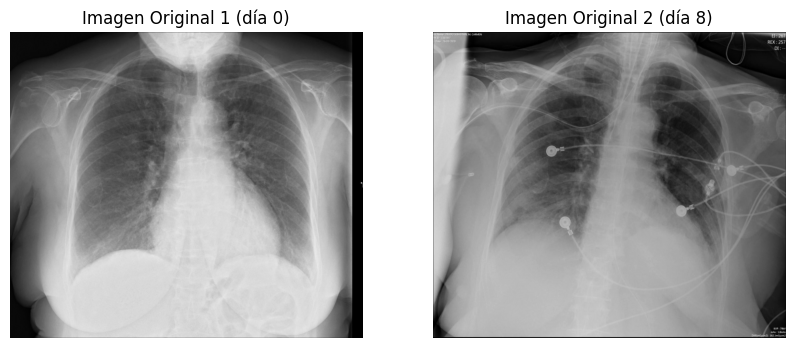

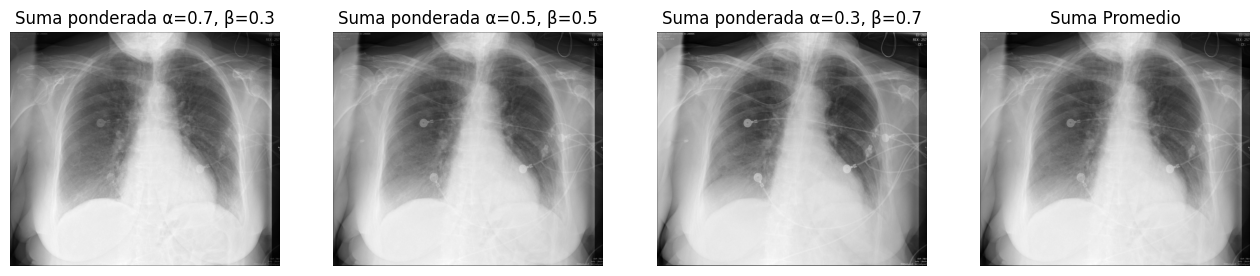

In [6]:
# Mostrar imágenes originales
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(imagen1, cmap="gray")
plt.title("Imagen Original 1 (día 0)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagen2, cmap="gray")
plt.title("Imagen Original 2 (día 8)")
plt.axis("off")
plt.show()

# Mostrar resultados de la suma
plt.figure(figsize=(16, 5))
for i, ((alpha, beta), img) in enumerate(zip(pesos, sumas_ponderadas)):
    plt.subplot(1, 4, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(f"Suma ponderada α={alpha}, β={beta}")
    plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(imagen_promedio, cmap="gray")
plt.title("Suma Promedio")
plt.axis("off")
plt.show()

**Resultado:**
- **Pesos 0.7/0.3:** la imagen se parece más a la del día 0 (la que tiene mayor peso), con apenas un "fantasma" de la del día 8.
- **Pesos 0.3/0.7:** ocurre lo contrario, y se distinguen mejor los electrodos y cables que solo aparecen en el estudio del día 8.
- **Pesos 0.5/0.5:** ambas imágenes aportan lo mismo, por eso es igual a la suma promedio.

Como las radiografías no están perfectamente alineadas (el paciente no estaba en la misma posición y la exposición de cada estudio fue distinta), algunos contornos, como las clavículas, las costillas y el borde del corazón, se ven **duplicados o borrosos**. La suma integra la información de las dos imágenes en una sola, pero para que la combinación sea útil clínicamente las imágenes deben registrarse (alinearse) primero. Como cada imagen se multiplica por un peso menor a 1 y los pesos suman 1, el brillo general se mantiene dentro del rango 0–255.

## Ejercicio 2. Resta de imágenes

**1. Resta directa.** Se resta la radiografía del día 8 a la del día 0 con `cv2.subtract`. En imágenes de 8 bits, una resta puede dar valores negativos. OpenCV los **satura en 0**, así que solo se conservan las zonas donde la primera imagen es más brillante que la segunda; las diferencias en sentido contrario se pierden.

**2. Diferencia absoluta.** `cv2.absdiff` calcula $\lvert I_1 - I_2 \rvert$, por lo que todas las diferencias quedan positivas sin importar qué imagen sea más brillante. Así se muestran **todos** los cambios entre los dos estudios.

In [7]:
# Resta directa (los valores negativos se saturan a 0)
resta = cv2.subtract(imagen1, imagen2)

# Diferencia absoluta para evitar valores negativos
diferencia_abs = cv2.absdiff(imagen1, imagen2)

print("Píxeles en 0 en la resta directa  :", f"{np.mean(resta == 0)*100:.1f} %")
print("Píxeles en 0 en la resta absoluta :", f"{np.mean(diferencia_abs == 0)*100:.1f} %")

Píxeles en 0 en la resta directa  : 27.5 %
Píxeles en 0 en la resta absoluta : 0.6 %


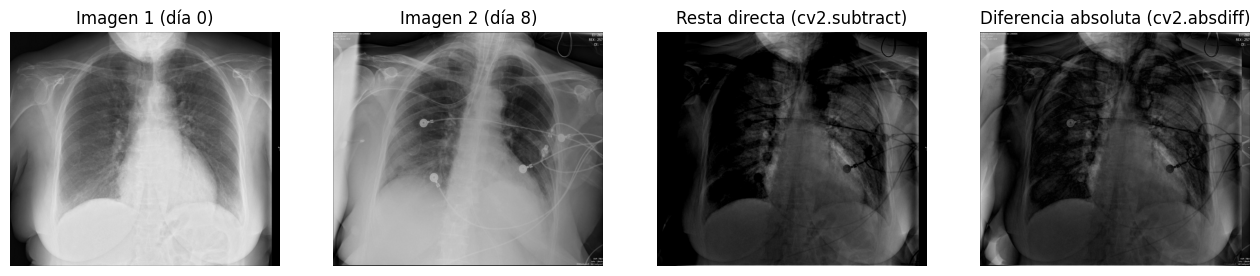

In [8]:
# Mostrar imágenes originales y resultados
plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.imshow(imagen1, cmap='gray')
plt.title("Imagen 1 (día 0)")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(imagen2, cmap='gray')
plt.title("Imagen 2 (día 8)")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(resta, cmap='gray')
plt.title("Resta directa (cv2.subtract)")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(diferencia_abs, cmap='gray')
plt.title("Diferencia absoluta (cv2.absdiff)")
plt.axis("off")

plt.show()

**Resultado:**
- **Zonas sin cambios:** en ambas restas quedan oscuras, porque sus valores casi se cancelan.
- **Resta directa:** se ve más oscura y con menos información, ya que todas las diferencias negativas se convirtieron en 0. Solo aparecen las regiones que eran más claras en el día 0 que en el día 8.
- **Diferencia absoluta:** muestra todos los cambios. Se ven claramente los electrodos y cables que solo existen en el estudio del día 8, las diferencias de intensidad en los campos pulmonares y líneas brillantes en los bordes de las costillas, las clavículas y el corazón. Estas líneas se deben a que el paciente no estaba exactamente en la misma posición. También influye que el estudio del día 8 tiene una exposición distinta, ya que se ve más claro en general.

Esto demuestra que la resta es una herramienta útil para detectar cambios entre estudios, pero que requiere imágenes bien alineadas para que solo resalten los cambios reales.

## Ejercicio 3. Multiplicación por un factor

Multiplicar cada píxel por un factor $k$ modifica el brillo de la imagen:
- $k > 1$: aclara la imagen.
- $k < 1$: la oscurece.

Siguiendo el notebook de la clase, se usa `cv2.multiply` con el factor en formato flotante y después `cv2.convertScaleAbs`, que redondea y limita los valores al rango 0–255. Se compararon tres factores para cada radiografía de la Parte I: **0.5, 1.5 y 2.0**.

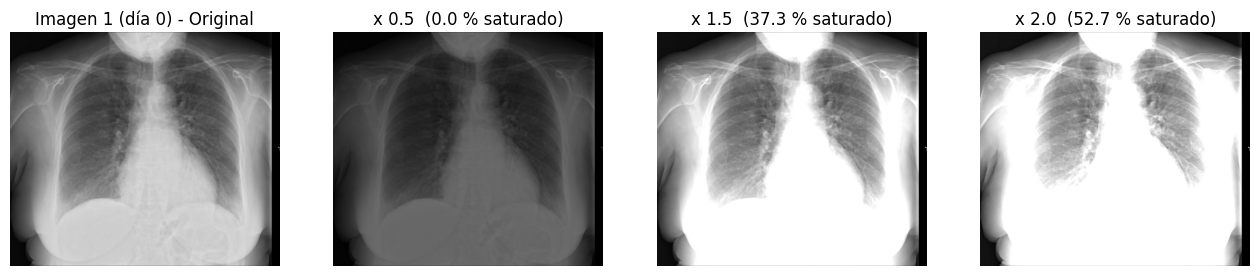

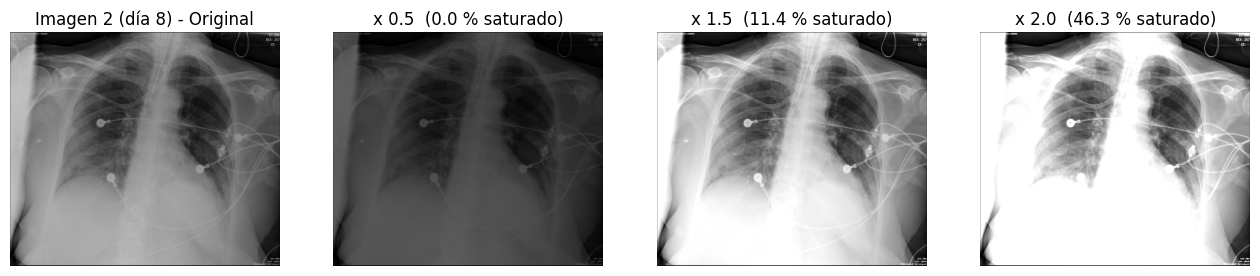

In [9]:
# Factores de multiplicación
factores = [0.5, 1.5, 2.0]

imagenes = {"Imagen 1 (día 0)": imagen1, "Imagen 2 (día 8)": imagen2}

for nombre, img in imagenes.items():
    plt.figure(figsize=(16, 4.5))
    plt.subplot(1, 4, 1)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.title(f"{nombre} - Original")
    plt.axis("off")

    for i, factor in enumerate(factores):
        # Multiplicar la imagen por el factor
        img_multiplicada = cv2.multiply(img, np.array([factor], dtype=np.float32))
        # Convertir la imagen a uint8 para visualización correcta
        img_multiplicada = cv2.convertScaleAbs(img_multiplicada)

        saturados = np.mean(img_multiplicada == 255) * 100
        plt.subplot(1, 4, i + 2)
        plt.imshow(img_multiplicada, cmap='gray', vmin=0, vmax=255)
        plt.title(f"x {factor}  ({saturados:.1f} % saturado)")
        plt.axis("off")
    plt.show()

**Resultado:**
- **Factor 0.5:** las dos radiografías se oscurecen a la mitad del brillo. Se conservan todas las estructuras, pero con menos contraste visual, y las zonas pulmonares casi se pierden en el fondo.
- **Factor 1.5:** las imágenes se aclaran. Los campos pulmonares, que son oscuros, se vuelven más visibles, pero las zonas que ya eran claras (columna, corazón, diafragma, abdomen) empiezan a **saturarse en blanco** (255), y ahí se pierde detalle.
- **Factor 2.0:** el efecto es más fuerte. Una gran parte de la imagen queda saturada y se pierden los bordes de los huesos y del mediastino; solo los pulmones conservan algo de textura.

El porcentaje de píxeles saturados de cada título confirma que, al multiplicar por un factor mayor a 1, se gana brillo pero se pierde información en las zonas claras. Por eso conviene elegir el factor según la región que se quiere observar.

## Ejercicio 4. Multiplicación elemento por elemento

Se multiplica cada píxel de la imagen 1 por el píxel correspondiente de la imagen 2. Si se multiplican directamente dos imágenes `uint8`, el resultado puede llegar hasta 255 × 255 = 65 025, y OpenCV lo satura a 255, dejando casi toda la imagen en blanco. Para evitarlo, la multiplicación se hace en **flotante** y el resultado se divide entre 255 para regresarlo al rango 0–255:

$$R(x,y) = \frac{I_1(x,y)\cdot I_2(x,y)}{255}$$

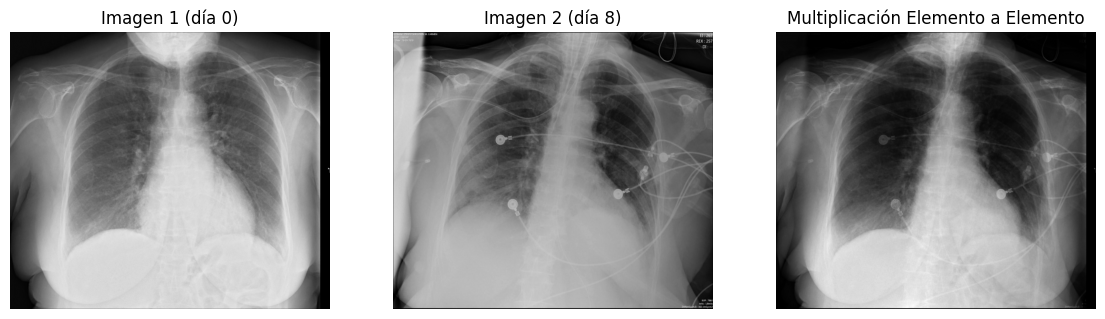

In [10]:
# Multiplicación elemento a elemento (en flotante y normalizada a 0-255)
img_multiplicada = cv2.multiply(imagen1.astype(np.float32), imagen2.astype(np.float32)) / 255

# Convertir la imagen resultante a uint8
img_multiplicada = cv2.convertScaleAbs(img_multiplicada)

# Mostrar imágenes originales y resultado
plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagen1, cmap='gray')
plt.title("Imagen 1 (día 0)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(imagen2, cmap='gray')
plt.title("Imagen 2 (día 8)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(img_multiplicada, cmap='gray')
plt.title("Multiplicación Elemento a Elemento")
plt.axis("off")

plt.show()

**Resultado:** la imagen resultante es más oscura que las originales, porque al dividir entre 255 un píxel solo queda brillante si es claro **en las dos imágenes**. Las estructuras densas que aparecen en ambos estudios, como la columna, el corazón, el diafragma y el abdomen, se conservan claras. Las zonas que son oscuras en al menos una de las imágenes, como los campos pulmonares o los bordes que no coinciden por la diferencia de posición, se atenúan. La operación funciona como un "Y" en escala de grises: resalta lo que tienen en común ambas imágenes.

**Aplicaciones biomédicas:**
- **Aplicación de máscaras:** multiplicar una imagen por una máscara binaria (valores 0 y 1) deja solo la región de interés, por ejemplo un pulmón, un órgano o un tumor segmentado, y elimina el resto.
- **Corrección de inhomogeneidades:** en resonancia magnética se corrige la variación de intensidad producida por las bobinas multiplicando la imagen por un mapa de corrección.
- **Fusión multimodal:** permite combinar imágenes registradas de distintas modalidades (por ejemplo PET y TC, o un mapa de probabilidad sobre una RM) para resaltar las zonas donde coinciden la anatomía y la actividad.
- **Ponderación espacial:** se pueden aplicar ventanas o mapas de peso para dar más importancia a una región durante el análisis.

---
# **Parte II. Operaciones lógicas**

## Ejercicio 1. Ecualización

Se usa una radiografía de tórax con **bajo contraste**: casi todos sus píxeles están concentrados en un rango estrecho de grises, por lo que la imagen se ve velada y es difícil distinguir los campos pulmonares, el corazón y las costillas.

1. La imagen se carga en escala de grises.
2. Con `cv2.calcHist` (canal 0, sin máscara, 256 bins y rango 0–256) se obtiene su histograma.
3. `cv2.equalizeHist` redistribuye los niveles de intensidad usando el histograma acumulado (CDF): los niveles más frecuentes se separan entre sí y la imagen termina ocupando todo el rango de 0 a 255.
4. Se calcula el histograma de la imagen ecualizada para comparar ambas distribuciones.

In [11]:
# Cargar la imagen en escala de grises
imagen = cv2.imread("RX_bajo_contraste.jpg", cv2.IMREAD_GRAYSCALE)

# Aplicar ecualización de histograma
imagen_ecualizada = cv2.equalizeHist(imagen)

# Calcular histogramas antes y después
hist_original = cv2.calcHist([imagen], [0], None, [256], [0,256])
hist_ecualizada = cv2.calcHist([imagen_ecualizada], [0], None, [256], [0,256])

print(f"Original   -> media: {imagen.mean():.1f} | desviación estándar: {imagen.std():.1f}")
print(f"Ecualizada -> media: {imagen_ecualizada.mean():.1f} | desviación estándar: {imagen_ecualizada.std():.1f}")

Original   -> media: 158.5 | desviación estándar: 26.3
Ecualizada -> media: 128.9 | desviación estándar: 74.0


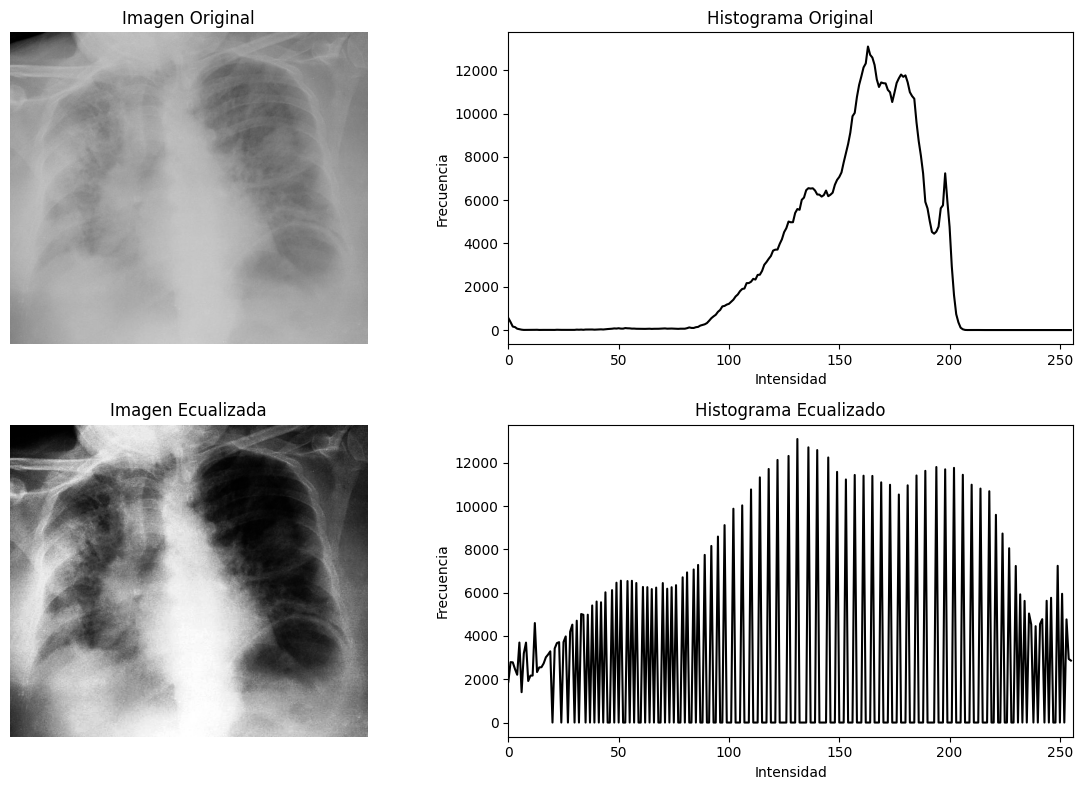

In [12]:
# Mostrar imágenes y histogramas
plt.figure(figsize=(12,8))

# Imagen Original
plt.subplot(2,2,1)
plt.imshow(imagen, cmap="gray", vmin=0, vmax=255)
plt.title("Imagen Original")
plt.axis("off")

# Histograma Original
plt.subplot(2,2,2)
plt.plot(hist_original, color="black")
plt.title("Histograma Original")
plt.xlabel("Intensidad")
plt.ylabel("Frecuencia")
plt.xlim([0,256])

# Imagen Ecualizada
plt.subplot(2,2,3)
plt.imshow(imagen_ecualizada, cmap="gray", vmin=0, vmax=255)
plt.title("Imagen Ecualizada")
plt.axis("off")

# Histograma Ecualizado
plt.subplot(2,2,4)
plt.plot(hist_ecualizada, color="black")
plt.title("Histograma Ecualizado")
plt.xlabel("Intensidad")
plt.ylabel("Frecuencia")
plt.xlim([0,256])

plt.tight_layout()
plt.show()

**Resultado:**
- **Histograma original:** casi todos los píxeles se concentran en una franja estrecha, aproximadamente entre 90 y 205, sin valores oscuros ni blancos puros. Por eso la radiografía se ve velada y grisácea, con poca diferencia entre los pulmones, el corazón y las costillas.
- **Después de la ecualización:** el histograma se **extiende por todo el rango 0–255** y la desviación estándar pasa de 26 a 74, lo que indica un contraste mucho mayor. En la imagen ecualizada los campos pulmonares se ven más oscuros y se distinguen mejor las opacidades de la neumonía, la silueta cardiaca, las costillas y la tráquea.
- **Forma de "peine":** el histograma ecualizado muestra barras con huecos entre ellas. Esto ocurre porque la ecualización reasigna los pocos niveles originales a nuevas posiciones repartidas por todo el rango, pero no crea niveles de gris nuevos; lo que se obtiene es un histograma más plano y extendido, no perfectamente uniforme.

Como contraparte, la ecualización también amplifica el ruido y puede exagerar zonas que no son de interés, como el fondo o el abdomen, porque mejora el contraste de toda la imagen por igual.